This dataset is about the sales of a cafe shop in the year 2023. 

In [81]:
# Loading the dataset
import pandas as pd 

df = pd.read_csv("/Users/anamleen/Downloads/dirty_cafe_sales.csv")

print(df.head())  

  Transaction ID    Item Quantity Price Per Unit Total Spent  Payment Method  \
0    TXN_1961373  Coffee        2            2.0         4.0     Credit Card   
1    TXN_4977031    Cake        4            3.0        12.0            Cash   
2    TXN_4271903  Cookie        4            1.0       ERROR     Credit Card   
3    TXN_7034554   Salad        2            5.0        10.0         UNKNOWN   
4    TXN_3160411  Coffee        2            2.0         4.0  Digital Wallet   

   Location Transaction Date  
0  Takeaway       2023-09-08  
1  In-store       2023-05-16  
2  In-store       2023-07-19  
3   UNKNOWN       2023-04-27  
4  In-store       2023-06-11  


In [82]:
print(df.shape[0])

10000


In [83]:
print(df.columns)

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='object')


In [84]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB
None


'Object' means that everything is in the form of text, which is not accurate as because Quantity, Price, Total Spent are all numbers and Transaction Date should be in Date form. They all show as text because of the UNKNOWN and ERROR values in each column, which are the fake missing values. So UNKNOWN and ERROR must be converted to NaN.

In [85]:
# Replace ERROR and UNKNOWN with NaN
df = pd.read_csv("/Users/anamleen/Downloads/dirty_cafe_sales.csv", na_values=["ERROR", "UNKNOWN"])

print(df.head())


  Transaction ID    Item  Quantity  Price Per Unit  Total Spent  \
0    TXN_1961373  Coffee       2.0             2.0          4.0   
1    TXN_4977031    Cake       4.0             3.0         12.0   
2    TXN_4271903  Cookie       4.0             1.0          NaN   
3    TXN_7034554   Salad       2.0             5.0         10.0   
4    TXN_3160411  Coffee       2.0             2.0          4.0   

   Payment Method  Location Transaction Date  
0     Credit Card  Takeaway       2023-09-08  
1            Cash  In-store       2023-05-16  
2     Credit Card  In-store       2023-07-19  
3             NaN       NaN       2023-04-27  
4  Digital Wallet  In-store       2023-06-11  


In [86]:
df.isna().sum()

Transaction ID         0
Item                 969
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64

In [87]:
# Fix Data Types
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], errors='coerce')
df.dtypes

Transaction ID              object
Item                        object
Quantity                   float64
Price Per Unit             float64
Total Spent                float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
dtype: object

In [88]:
# Duplicate Rows
initial_rows = len(df)
df = df.drop_duplicates()   
print("Removed", initial_rows - len(df), "duplicate rows")

Removed 0 duplicate rows


In [89]:
# Convert Quantity into non-decimal and drop rows with missing values (NaN)
df = df.dropna()

df["Quantity"] = df["Quantity"].astype(int)   # 2.0 -> 2

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3089 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    3089 non-null   object        
 1   Item              3089 non-null   object        
 2   Quantity          3089 non-null   int64         
 3   Price Per Unit    3089 non-null   float64       
 4   Total Spent       3089 non-null   float64       
 5   Payment Method    3089 non-null   object        
 6   Location          3089 non-null   object        
 7   Transaction Date  3089 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 217.2+ KB


In [90]:
# Returns entire dataset with rows deleted that have NaN values (from row 1 it skips to to 4 because row 2 and 3 have NaN values)
print(df.head()) 

   Transaction ID      Item  Quantity  Price Per Unit  Total Spent  \
0     TXN_1961373    Coffee         2             2.0          4.0   
1     TXN_4977031      Cake         4             3.0         12.0   
4     TXN_3160411    Coffee         2             2.0          4.0   
10    TXN_2548360     Salad         5             5.0         25.0   
12    TXN_7619095  Sandwich         2             4.0          8.0   

    Payment Method  Location Transaction Date  
0      Credit Card  Takeaway       2023-09-08  
1             Cash  In-store       2023-05-16  
4   Digital Wallet  In-store       2023-06-11  
10            Cash  Takeaway       2023-11-07  
12            Cash  In-store       2023-05-03  


The dataset is clean. The columns are in their appropriate formats, that is, Quantity, Price and Total are in the form of integers and Transaction Date is in the form of Date. All the rows containing NaN values have been removed, and the dataset has been verified to not have any duplicates. Now the dataset can be plotted as charts. 

## Chart

After cleaning the data, the data is plotted in charts to show revenue of each individual item and the monthly sales of the shop in 2023. 

In [91]:
import matplotlib.pyplot as plt

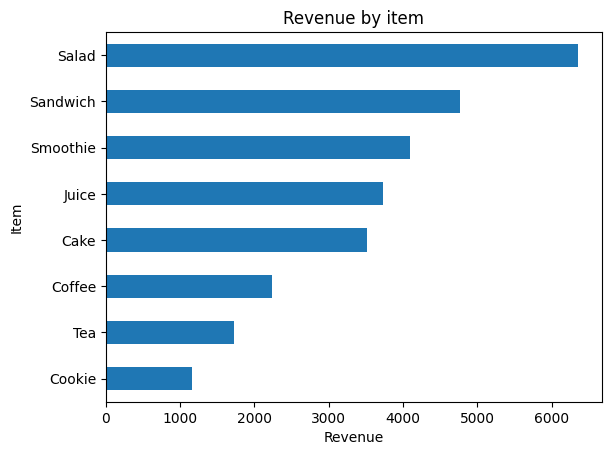

In [92]:
# Revenue by item

df.groupby('Item')['Total Spent'].sum().sort_values().plot.barh(title="Revenue by item")
plt.xlabel("Revenue")
plt.show()  

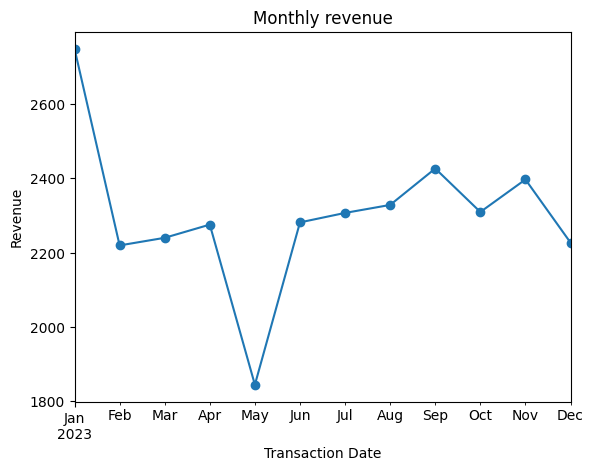

In [93]:
# Monthly Revenue 

monthly = df.groupby(df["Transaction Date"].dt.to_period("M"))["Total Spent"].sum()
monthly.plot(marker="o", title="Monthly revenue")
plt.ylabel("Revenue")
plt.show()

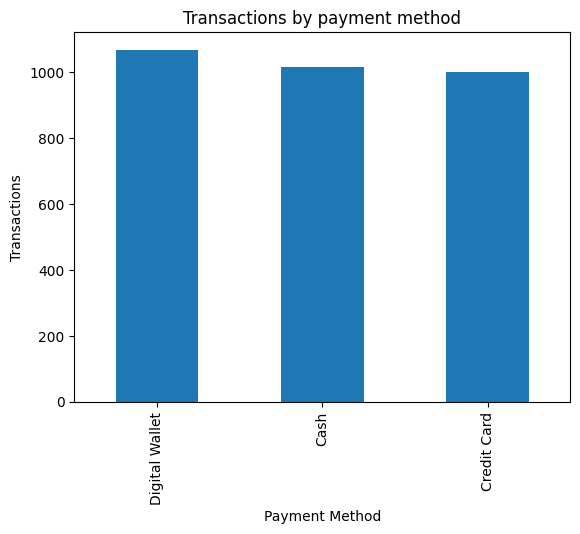

In [94]:
df["Payment Method"].value_counts().plot.bar(title="Transactions by payment method")
plt.ylabel("Transactions")
plt.show()